# Этап 3. Стационарность и декомпозиция углублённо

#### Матрица решений ADF+KPSS · сезонное дифференцирование · Box-Cox · STL

In [2]:
# Импорты: библиотеки + хелпер, подавление спама предупреждений от KPSS.
import sys
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import boxcox
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.helpers import save_fig, save_table

warnings.simplefilter("ignore", InterpolationWarning)
plt.rcParams["figure.figsize"] = (10, 4)

In [3]:
# Загрузка M5 и сборка ежедневного ряда магазина CA_3
DATA = ROOT / "data" / "raw"
sales = pd.read_csv(DATA / "sales_train_validation.csv")
calendar = pd.read_csv(DATA / "calendar.csv")

day_cols = [c for c in sales.columns if c.startswith("d_")]
ca_3 = sales.loc[sales["store_id"] == "CA_3", day_cols].sum()

s = pd.Series(ca_3.values,
             index=pd.to_datetime(calendar["date"].iloc[:len(day_cols)]),
             name="sales").astype("float64")
print(f"{s.index.mean().date()} -> {s.index.max().date()} | дней: {len(s)} | пропусков: {s.isna().sum()}")

2013-09-11 -> 2016-04-24 | дней: 1913 | пропусков: 0


## 1. Матрица решений ADF + KPSS

In [4]:
# Функция теста
def stationarity_report(series, name):
    """ADF и KPSS на одном ряде + вердикт по матрице решений."""
    x = series.dropna()
    adf_stat, adf_p, *_ = adfuller(x, autolag="AIC", result_object=False)
    kpss_stat, kpss_p, *_ = kpss(x, regression="c", nlags="auto", result_object=False)

    if adf_p < 0.05 and kpss_p > 0.05:
        verdict = "стационарен"
    elif adf_p >= 0.05 and kpss_p <= 0.05:
        verdict = "нестационарен"
    else:
        verdict = "тесты расходятся -> трактуем как не стационарный"

    return {
        "ряд": name,
        "ADF stat": round(adf_stat, 3), "ADF p": round(adf_p, 4),
        "KPSS stat": round(kpss_stat, 3), "KPSS p": round(kpss_p, 4),
        "вердикт": verdict
    }

In [5]:
# Матрица для четырёх вариантов ряда: уровни, diff(1), diff(7), diff(1)+diff(7).
variants = {
    "уровни (как есть)": s,
    "+ diff(1)": s.diff(),
    "+ diff(7) - сезонные": s.diff(7),
    "+ diff(1) и diff(7)": s.diff().diff(7),
}

matrix = pd.DataFrame([stationarity_report(x, name) for name, x in variants.items()])
save_table(matrix, "03_stat_stationarity_matrix")
matrix

,ряд,ADF stat,ADF p,KPSS stat,KPSS p,вердикт
0,уровни (как есть),-2.397,0.1425,4.556,0.01,нестационарен
1,+ diff(1),-20.337,0.0000,0.028,0.10,стационарен
2,+ diff(7) - сезонные,-21.268,0.0000,0.021,0.10,стационарен
3,+ diff(1) и diff(7),-21.092,0.0000,0.010,0.10,стационарен


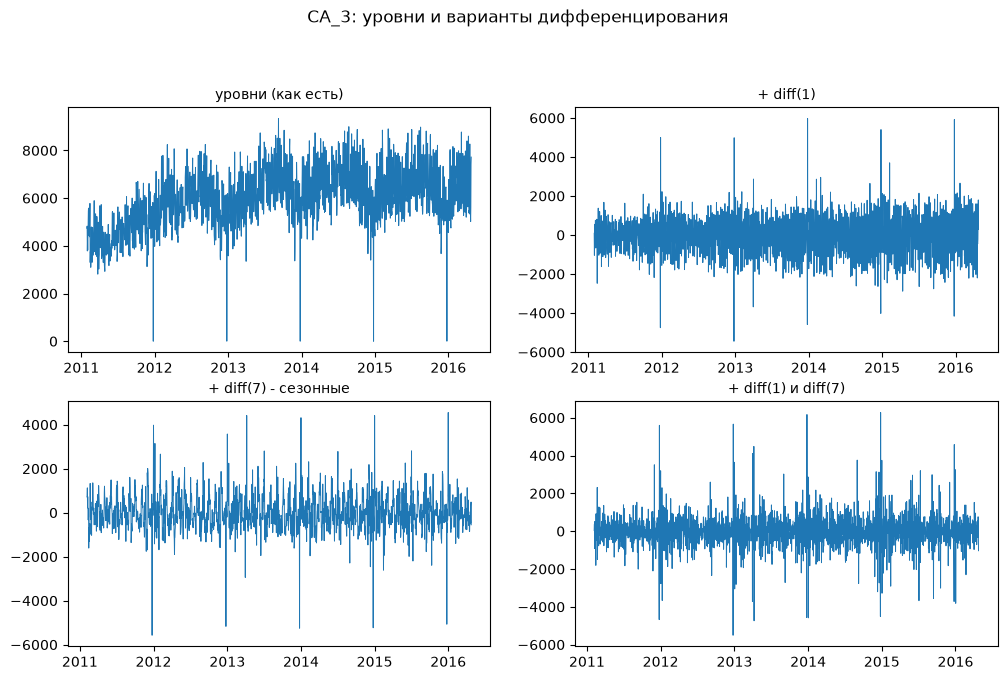

In [18]:
# Визуальное сравнение тех же четырёх вариантов
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (name, x) in zip(axes.ravel(), variants.items()):
    ax.plot(x, lw=0.7)
    ax.set_title(name, fontsize=10)
fig.suptitle("CA_3: уровни и варианты дифференцирования", y=1.02)
save_fig(fig, "03_stat_differencing_comparison")

## 2. Дисперсия и Box-Cox

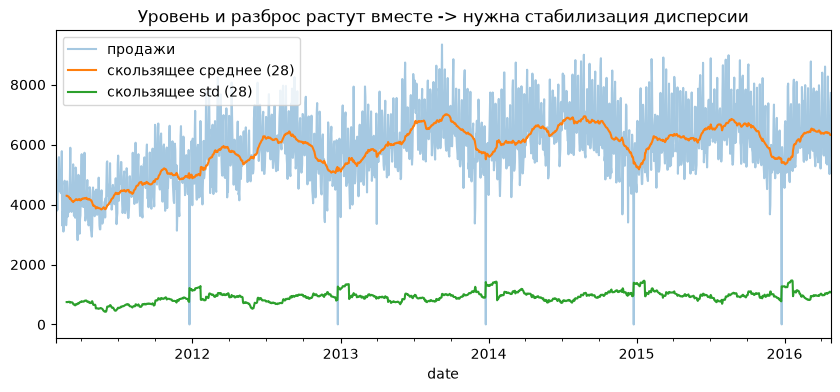

In [7]:
# Доказательство проблемы №2: скользящее среднее и скользящее std растут вместе.
roll = s.rolling(28)
ax = s.plot(alpha=0.4, label="продажи")
roll.mean().plot(ax=ax, label="скользящее среднее (28)")
roll.std().plot(ax=ax, label="скользящее std (28)")
ax.legend()
ax.set_title("Уровень и разброс растут вместе -> нужна стабилизация дисперсии")
save_fig(ax, "03_stat_variance_growth")

In [8]:
# Коэффициент вариации по годам — численное подтверждение того же эффекта.
yearly = s.groupby(s.index.year).agg(mean="mean", std="std")
yearly["SV, %"] = (yearly["std"] / yearly["mean"] * 100).round(1)
save_table(yearly.reset_index(), "03_stat_yearly_cv")
yearly

,mean,std,"SV, %"
date,,,
2011,4512.839763,830.380692,18.4
2012,5736.901639,984.838679,17.2
2013,6163.378082,1060.369314,17.2
2014,6341.249315,1078.767251,17.0
2015,6237.679452,1062.972684,17.0
2016,6319.173913,1006.302362,15.9


In [9]:
# Сама трансформация: λ подбирается автоматически
# Box-Cox требует строго положительных значений — в ряду есть нулевой день (Рождество)
s_pos = s[s > 0]
bc_values, lam = boxcox(s_pos.values)
s_bc = pd.Series(bc_values, index=s_pos.index, name="sales_boxcox")
print(f"λ = {lam:.3f}  ->  λ≈0 был бы логарифмом, λ≈1 — трансформация не нужна")

λ = 1.077  ->  λ≈0 был бы логарифмом, λ≈1 — трансформация не нужна


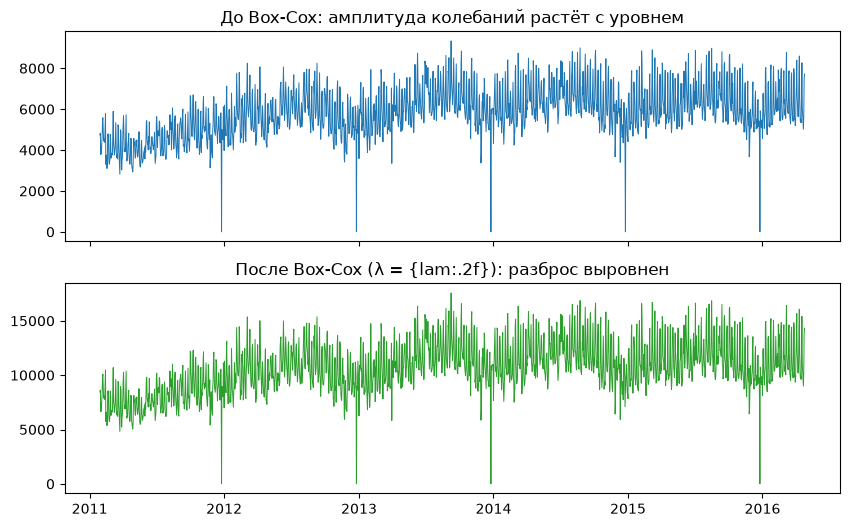

In [10]:
# До/после — амплитуда колебаний перестала зависеть от уровня.
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(s, lw=0.7)
axes[0].set_title("До Box-Cox: амплитуда колебаний растёт с уровнем")
axes[1].plot(s_bc, lw=0.7, color="tab:green")
axes[1].set_title("После Box-Cox (λ = {lam:.2f}): разброс выровнен")
save_fig(fig, "03_stat_boxcox_before_after")

In [11]:
# Матрица ADF+KPSS уже на трансформированном ряде
bc_variants = {
    "Box-Cox уровни": s_bc,
    "Box-Cox + diff(1)": s_bc.diff(),
    "Box-Cox + diff(1)+diff(7)": s_bc.diff(1).diff(7),
}

bc_matrix = pd.DataFrame([stationarity_report(x, name) for name, x in bc_variants.items()])
save_table(bc_matrix, "03_stat_adf_kpss_boxcox")
bc_matrix

,ряд,ADF stat,ADF p,KPSS stat,KPSS p,вердикт
0,Box-Cox уровни,-2.368,0.1509,4.632,0.01,нестационарен
1,Box-Cox + diff(1),-20.317,0.0000,0.029,0.10,стационарен
2,Box-Cox + diff(1)+diff(7),-20.886,0.0000,0.008,0.10,стационарен


## 3. STL: декомпозиция с изменяющейся сезонностью

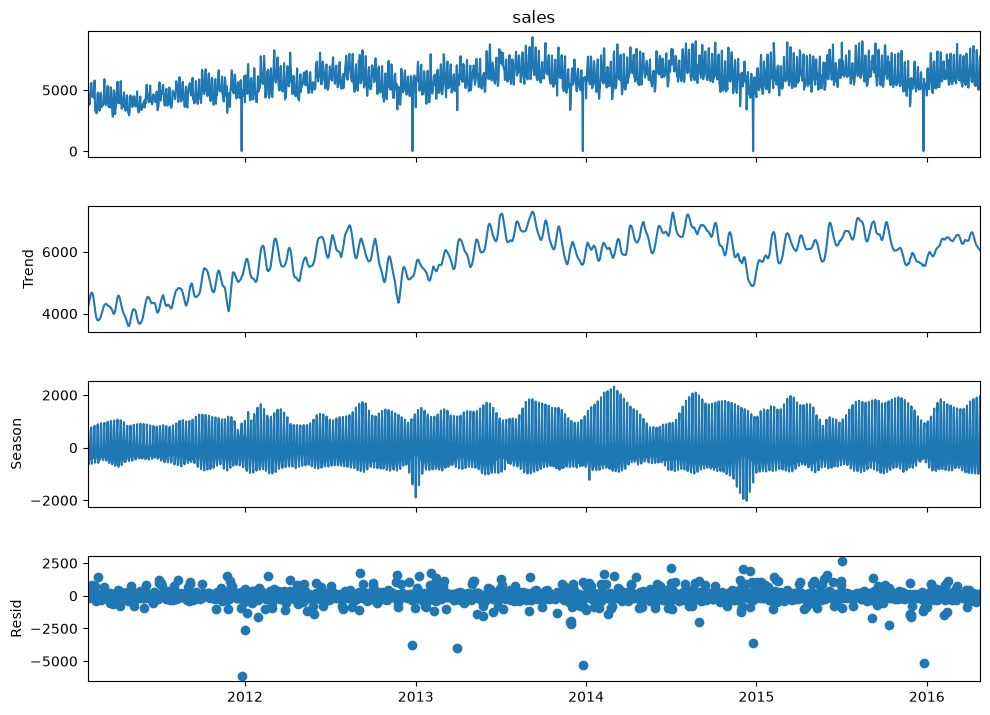

In [12]:
# STL-разложение на тренд / сезонность / остаток.
res = STL(s, period=7, robust=True).fit()

fig = res.plot()
fig.set_size_inches(10, 8)
save_fig(fig, "03_stat_stl_components")

In [13]:
# Численное сравнение с классической декомпозицией
cl = seasonal_decompose(s, model="additive", period=7)

compare = pd.DataFrame({
    "STL": [res.seasonal.std(), res.resid.std()],
    "классическая": [cl.seasonal.std(), cl.resid.std()],
}, index=["std сезонной компоненты", "std остатков"])
save_table(compare.round(1).rename_axis("метрика").reset_index(), "03_stat_stl_vs_classical")
compare.round(1)

,STL,классическая
std сезонной компоненты,774.8,699.6
std остатков,481.0,483.1


In [14]:
# Проверка главного преимущества STL: меняется ли форма недельной сезонности от года к году.
drift = res.seasonal.groupby(res.seasonal.index.year).std().round(1).rename("std сезонной компоненты")
drift.index.name = "год"
save_table(drift.reset_index(), "03_stat_seasonal_drift")
drift

год
2011    574.8
2012    728.5
2013    792.7
2014    853.4
2015    826.7
2016    938.8
Name: std сезонной компоненты, dtype: float64

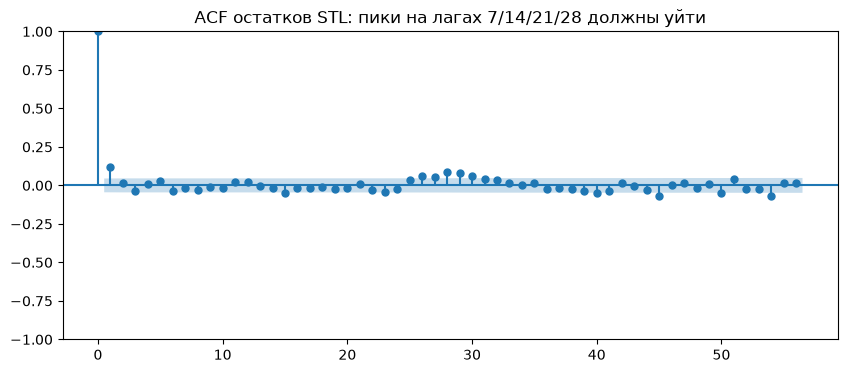

In [15]:
# Диагностика: ACF остатков STL — пики на 7/14/21/28 должны исчезнуть.
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(res.resid.dropna(), lags=56, ax=ax)
ax.set_title("ACF остатков STL: пики на лагах 7/14/21/28 должны уйти")
save_fig(fig, "03_stat_stl_residual_acf")

## Упражнение

In [16]:
wi2 = sales.loc[sales["store_id"] == "WI_2", day_cols].sum()
s2 = pd.Series(wi2.values, index=s.index, name="sales_wi2").astype("float64")
print(f"{s2.index.min().date()} -> {s2.index.max().date()} | дней: {len(s2)} | пропусков: {s2.isna().sum()}")

variants2 = {
    "уровни (как есть)": s2,
    "+ diff(1)": s2.diff(),
    "+ diff(7) — сезонные": s2.diff(7),
    "+ diff(1) и diff(7)": s2.diff().diff(7),
}

matrix2 = pd.DataFrame([stationarity_report(x, name) for name, x in variants2.items()])
save_table(matrix2, "03_stat_ex_wi2_matrix")
matrix2

2011-01-29 -> 2016-04-24 | дней: 1913 | пропусков: 0


,ряд,ADF stat,ADF p,KPSS stat,KPSS p,вердикт
0,уровни (как есть),-0.985,0.7587,5.636,0.01,нестационарен
1,+ diff(1),-25.980,0.0000,0.025,0.10,стационарен
2,+ diff(7) — сезонные,-14.533,0.0000,0.009,0.10,стационарен
3,+ diff(1) и diff(7),-25.056,0.0000,0.091,0.10,стационарен


In [17]:
bc_values2, lam2 = np.log1p(s2.values), 0.0
print(f"WI_2: λ = {lam2:.3f}  ->  λ≈0 был бы логарифмом, λ≈1 — трансформация не нужна")

WI_2: λ = 0.000  ->  λ≈0 был бы логарифмом, λ≈1 — трансформация не нужна


a) уровни WI_2: -0.985; 0.7587; 5.636; 0.01 · diff(1)+diff(7): -25.056; 0.0000; 0.091; 0.10

b) λ = 0.000

c) (d, D) = (1, 0), потому что после одного diff(1) ряд стал стационарным по обоим тестам одновременно